In [1]:
import os
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
from pydotthz import DotthzFile
from math_utils import get_fft, get_ifft
from scipy.signal import find_peaks
import scipy.constants
from tqdm import tqdm
from scipy.optimize import curve_fit

from thz_deconvolution import Deconvolution
from envelope import gaussian_kernel1d, convolve1d, envelope_hilbert
from estimate_noise import get_threshold_from_noise

from surface_extraction import detect_first_peak, get_thickness, save_surface_as_point_cloud, get_thz_file_from_path


In [2]:

path = Path("/Users/linus/Documents/COC_terrain/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_SPHERES_fine_scan/data_image_rfl")
path = Path("/Users/linus/Documents/COC_SPHERES_fine_scan_3/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_FULL_SPHERES_fine_scan/data_image_rfl")
# path = Path("/Users/linus/Documents/resolution_scan_A_high_res_6/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_SPHERES_ext_rng/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_terrain_res_target_2/data_image_rfl")
# path = Path("/Users/linus/Documents/DUST_surface_res_target_3d_3/data_image_rfl")
path = Path("/Users/linus/Documents/COC_PEBBLE_CoDA_T1a_2/data_image_rfl")
# path = Path("/Users/linus/Documents/Solid_ICE_PEBBLE_CoDA_T1a_2/data_image_rfl")
# path = Path("/Users/linus/Documents/SPIPA_ICE_PEBBLE_CoDA_T1a_2/data_image_rfl")

path = get_thz_file_from_path(path)

with DotthzFile(path) as psf_data:
    key = list(psf_data.keys())[0]
    dx = float(psf_data[key].metadata['dx [mm]'])
    dy = float(psf_data[key].metadata['dy [mm]'])
    x_min = float(psf_data[key].metadata['x_min [mm]'])
    x_max = float(psf_data[key].metadata['x_max [mm]'])
    y_min = float(psf_data[key].metadata['y_min [mm]'])
    y_max = float(psf_data[key].metadata['y_max [mm]'])
    width = int(float(psf_data[key].metadata['width']))
    height = int(float(psf_data[key].metadata['height']))
    datasets = psf_data[key].datasets

    # from the first dataset, extract the image:
    times = np.array(datasets["time"])
    traces = np.array(datasets["dataset"])

traces = traces[::, ::, :]

# Decon = Deconvolution(psf_path=Path("psf_data/psf.npz"), low_cut=0.1, high_cut=5.0)
Decon = Deconvolution(
    knife_edge_x_path=Path("psf_data/example_beam_width/measurement_x/data/1750085285.8557956_data.thz"),
    knife_edge_y_path=Path("psf_data/example_beam_width/measurement_y/data/1750163177.929295_data.thz"),
    low_cut=1.0, high_cut=5.0)

traces_old = traces
deconvolved_traces = Decon.apply_deconvolution(traces, x_min, x_max, width, y_min, y_max, height, max_iter=100)
traces = deconvolved_traces

p = traces[::, ::, times < 1912]
t = times[times < 1912]



Loading x raw measurements...
Loading y raw measurements...
Extracting the center of the PSF...
Center of the PSF: (-0.05000000000000071, -0.8499999999999996)
Creating 20 log-spaced filters...
Fitting beam widths...


100%|██████████| 20/20 [00:00<00:00, 74.19it/s]


Extracting the center of the PSF...
Center of the PSF: (-1.5500000000000003, -0.6500000000000004)
Creating 20 log-spaced filters...
Fitting beam widths...


100%|██████████| 20/20 [00:00<00:00, 76.39it/s]


Loading cached deconvolution result (hash: f39d991b...)


 13%|█▎        | 16/120 [00:01<00:07, 13.22it/s]/Users/linus/PycharmProjects/thz-3d-analysis/estimate_noise.py:30: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(gaussian, bin_centers, counts, p0=p0, maxfev=2000)
 17%|█▋        | 20/120 [00:01<00:07, 13.42it/s]

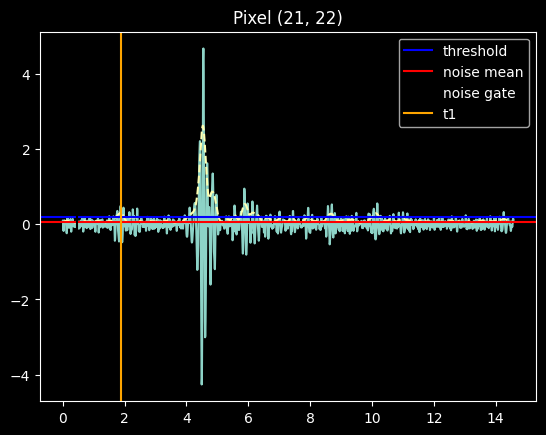

100%|██████████| 120/120 [00:08<00:00, 13.60it/s]


In [3]:
# p = traces[::, ::, :]
# t = times[:]

# p = p[p.shape[0]//2-10:p.shape[0]//2+10, ::2, :]
# x_min = -5
# x_max = 5
surface = np.zeros(p.shape[:2])
kernel = gaussian_kernel1d(sigma=6.0, radius=18)
for x in tqdm(range(p.shape[0])):
    for y in range(p.shape[1]):

        # f, a, arg = get_fft(t, p[x, y, :])
        #
        # a[f < 1.0] = 0
        # a[f > 5.0] = 0
        #
        # time, pulse = get_ifft(f, a, arg, t0=t[0])

        time, pulse = t, p[x, y, :]

        # t1 = detect_first_zero_crossing_after_peak(time, pulse, height=1.2)

        convolved_data_h = envelope_hilbert(pulse)
        convolved_data = convolve1d(np.abs(pulse), kernel)

        noise_mean = np.mean(np.abs(convolved_data[10:110]))
        noise_std = np.std(np.abs(convolved_data[10:110]))

        threshold = noise_mean + 5.0 * noise_std
        threshold = get_threshold_from_noise(convolved_data)

        if threshold is None:
            print(f"Could not determine threshold at pixel ({x}, {y}). Using default.")
            threshold = noise_mean + 5.0 * noise_std

        # threshold = 0.2 + convolved_data[0]

        t1 = detect_first_peak(time, convolved_data, height=threshold)
        t1h = detect_first_peak(time, convolved_data_h, height=threshold)

        # threshold = 0.08
        #
        # if x == 0 and y == 0:
        #     plt.plot(1000 * (time - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
        #              convolved_data )
        if x == 21 and y == 22:
            plt.title(f"Pixel ({x}, {y})")
            plt.plot(1000 * (time - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
                     pulse)
            plt.plot(1000 * (time - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
                     convolved_data, ls="--")
            # plt.plot(1000 * (time - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
            #          convolved_data_h, ls="--")
            plt.axhline(threshold, color='blue', label='threshold')
            plt.axhline(noise_mean, color='red', label='noise mean')
            plt.axvline(1000 * (time[60] - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
                        color='black', label='noise gate')
            plt.axvline(1000 * (t1 - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
                        color='orange', label='t1')
            # plt.axvline(1000 * (t1h - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
            #             color='green', ls="--", label="Hilbert peak")
            plt.legend()
            plt.show()

        if t1 is None:
            t1 = t[-1]
            # plt.title(f"Pixel ({x}, {y})")
            # plt.plot(1000 * (time - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
            #          pulse / np.max(pulse))
            # plt.plot(1000 * (time - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
            #          convolved_data, ls="--")
            # plt.plot(1000 * (time - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
            #          convolved_data_h, ls="--")
            # plt.axhline(threshold, color='k')
            # plt.axhline(noise_mean, color='red')
            # plt.axvline(1000 * (time[60] - time[0]) * scipy.constants.c / np.cos(np.radians(19)) / 2 * 1e-12,
            #             color='black')
            #
            # plt.show()
            # if y > 0:
            #     surface[x, y] = surface[x, y - 1]
            # else:
            #     surface[x, y] = surface[x - 1, y]
            surface[x, y] = - get_thickness(t[0], t1) * 1000  # in mm

        else:
            surface[x, y] = - get_thickness(t[0], t1) * 1000  # in mm

Saving 14400 points to /Users/linus/Documents/COC_PEBBLE_CoDA_T1a_2/data_image_rfl/1761041143.0295105_data.ply
Point cloud bounds: X[-32.00, 28.00], Y[-21.00, 39.00], Z[0.00, 14.55]
Point cloud saved successfully!
(120, 120) (120, 120)


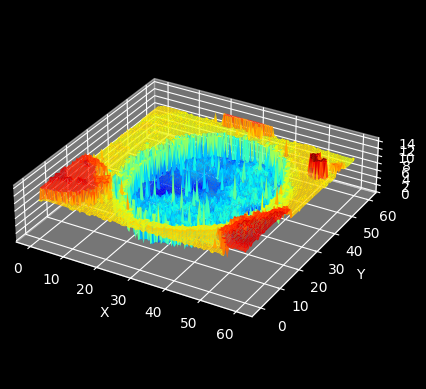

In [6]:
save_surface_as_point_cloud(surface, x_max, x_min, y_max, y_min,
                            path.with_suffix(".ply"), format='ply')

# Plot the surface as a 3D mesh
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define physical dimensions
nx, ny = surface.shape

# flip because of orientation
x_mm = np.linspace(0, y_max - y_min, ny)
y_mm = np.linspace(0, x_max - x_min, nx)
X, Y = np.meshgrid(x_mm, y_mm, indexing='xy')

print(X.shape, surface.shape)

ax.plot_surface(X, Y, surface, rcount=nx, ccount=ny, cmap='jet')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

x_range = x_mm.max() - x_mm.min()
y_range = y_mm.max() - y_mm.min()
z_range = surface.max() - surface.min()

ax.set_box_aspect([x_range, y_range, z_range])  # Match data aspect

plt.show()